# 03_Integration_Index — Component Analysis & Decomposition

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\project-1-refugee-integration


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
master = pd.read_parquet('data/processed/refugee_master_consolidated.parquet')
print(f'Loaded: {master.shape}')
print(f'Index range: {master["integration_index"].min():.2f} - {master["integration_index"].max():.2f}')

Loaded: (29506, 27)
Index range: 28.40 - 79.50


## 1. Integration Index Formula & Weights

In [4]:
weights = {
    'employment_rate': 0.20,
    'housing_access': 0.15,
    'education_enrollment': 0.20,
    'income_stability': 0.15,
    'legal_rights_score': 0.20,
    'social_cohesion': 0.10
}

print('Integration Index Formula:')
print('integration_index = (')
for component, weight in weights.items():
    print(f'    {component} × {weight} +')
print(')')
print(f'\nTotal weight: {sum(weights.values())}')

Integration Index Formula:
integration_index = (
    employment_rate × 0.2 +
    housing_access × 0.15 +
    education_enrollment × 0.2 +
    income_stability × 0.15 +
    legal_rights_score × 0.2 +
    social_cohesion × 0.1 +
)

Total weight: 1.0


## 2. Component Distributions

In [5]:
components = list(weights.keys())
stats = master[components].describe().round(2)
print(stats)

       employment_rate  housing_access  education_enrollment  \
count         29506.00        29506.00              29506.00   
mean             46.88           52.79                 68.69   
std              19.08           16.78                 12.12   
min               0.00            0.00                 24.42   
25%              33.13           40.90                 60.81   
50%              46.69           53.15                 68.20   
75%              59.38           64.77                 75.67   
max             100.00          100.00                100.00   

       income_stability  legal_rights_score  social_cohesion  
count          29506.00            29506.00         29506.00  
mean              42.90               58.86            48.77  
std               23.01               14.89            18.09  
min                0.00               17.01             0.00  
25%               27.12               48.45            37.14  
50%               44.11               57.79  

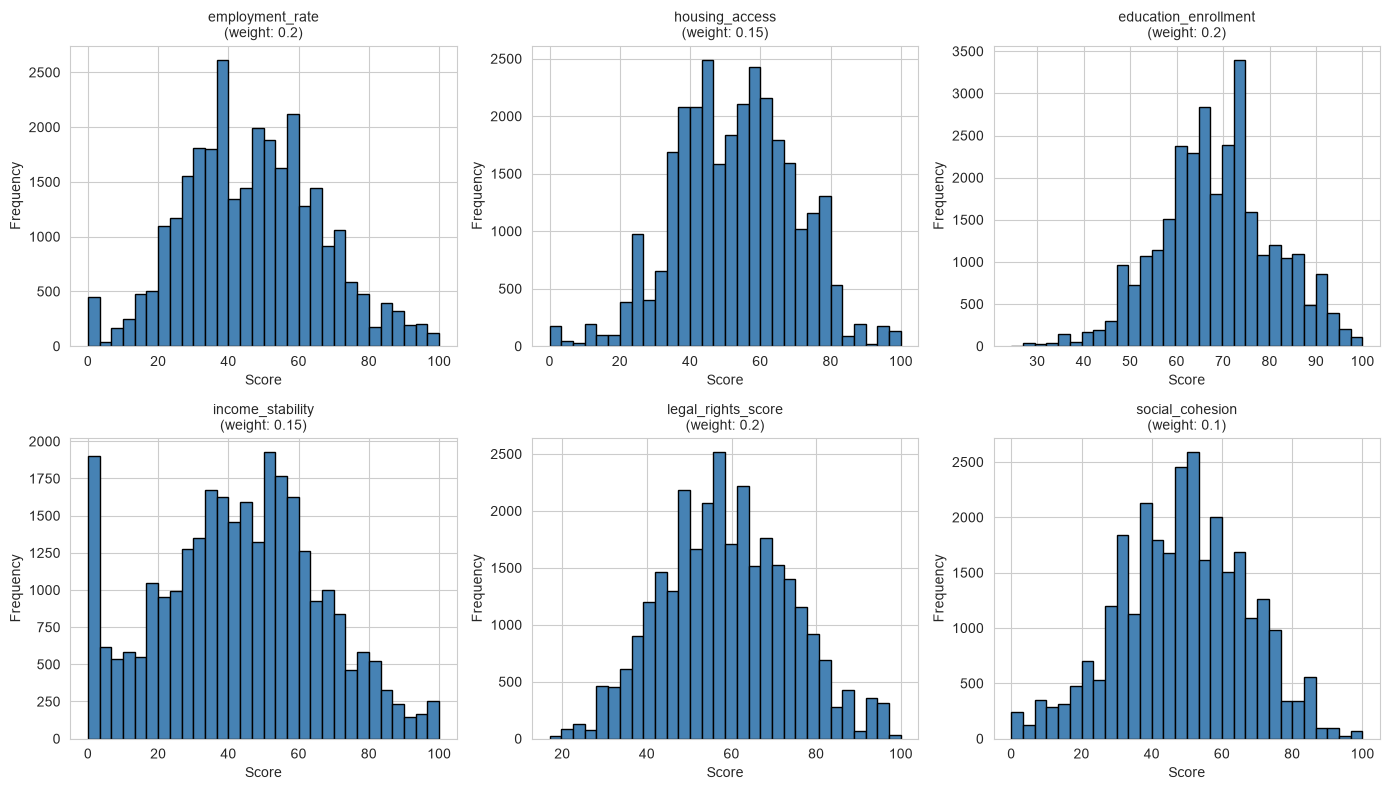

✓ Saved: 03_component_distributions.png


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for i, comp in enumerate(components):
    axes[i].hist(master[comp], bins=30, color='steelblue', edgecolor='black')
    axes[i].set_title(f'{comp}\n(weight: {weights[comp]})', fontsize=10)
    axes[i].set_xlabel('Score')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('output/03_component_distributions.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 03_component_distributions.png')

## 3. Weighted Contribution Analysis

In [7]:
# Calculate individual contributions
contributions = pd.DataFrame()
for comp, weight in weights.items():
    contributions[comp] = master[comp] * weight

contributions['total'] = contributions.sum(axis=1)
print('Contribution stats (in final index points):')
print(contributions.describe().round(2))

Contribution stats (in final index points):
       employment_rate  housing_access  education_enrollment  \
count         29506.00        29506.00              29506.00   
mean              9.38            7.92                 13.74   
std               3.82            2.52                  2.42   
min               0.00            0.00                  4.88   
25%               6.63            6.14                 12.16   
50%               9.34            7.97                 13.64   
75%              11.88            9.72                 15.13   
max              20.00           15.00                 20.00   

       income_stability  legal_rights_score  social_cohesion     total  
count          29506.00            29506.00         29506.00  29506.00  
mean               6.44               11.77             4.88     54.12  
std                3.45                2.98             1.81      8.64  
min                0.00                3.40             0.00     28.40  
25%           

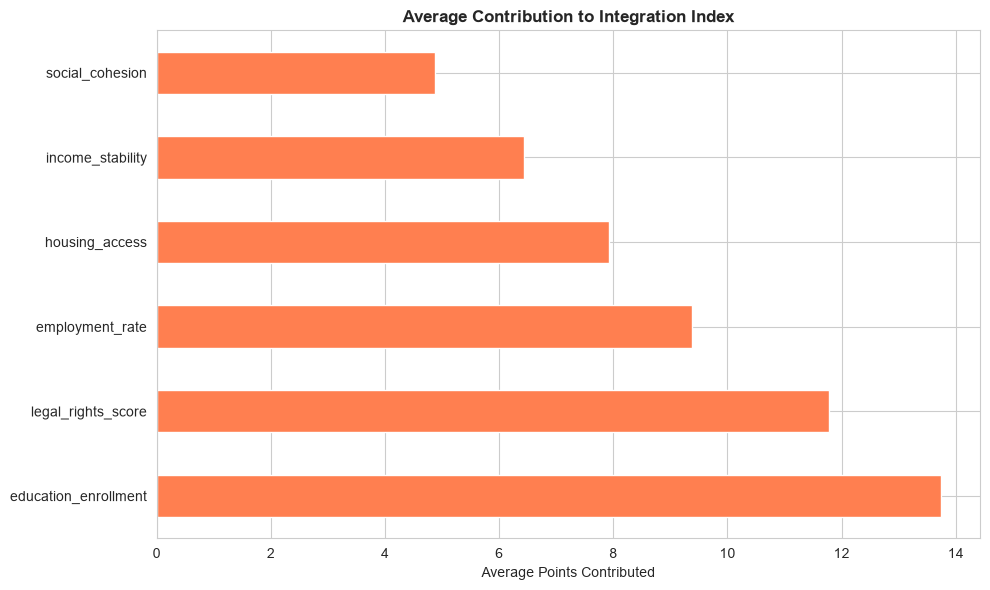

✓ Saved: 03_contribution_analysis.png


In [8]:
# Average contribution per component
avg_contributions = contributions[components].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
avg_contributions.plot(kind='barh', color='coral', ax=ax)
ax.set_title('Average Contribution to Integration Index', fontsize=12, fontweight='bold')
ax.set_xlabel('Average Points Contributed')
plt.tight_layout()
plt.savefig('output/03_contribution_analysis.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 03_contribution_analysis.png')

## 4. Index Tiers Classification

In [9]:
def classify_integration(score):
    if score >= 70:
        return 'High'
    elif score >= 50:
        return 'Medium'
    else:
        return 'Low'

master['integration_tier'] = master['integration_index'].apply(classify_integration)

tier_dist = master['integration_tier'].value_counts()
print('Integration Tier Distribution:')
for tier, count in tier_dist.items():
    pct = count / len(master) * 100
    print(f'  {tier}: {count} ({pct:.1f}%)')

Integration Tier Distribution:
  Medium: 18486 (62.7%)
  Low: 9941 (33.7%)
  High: 1079 (3.7%)


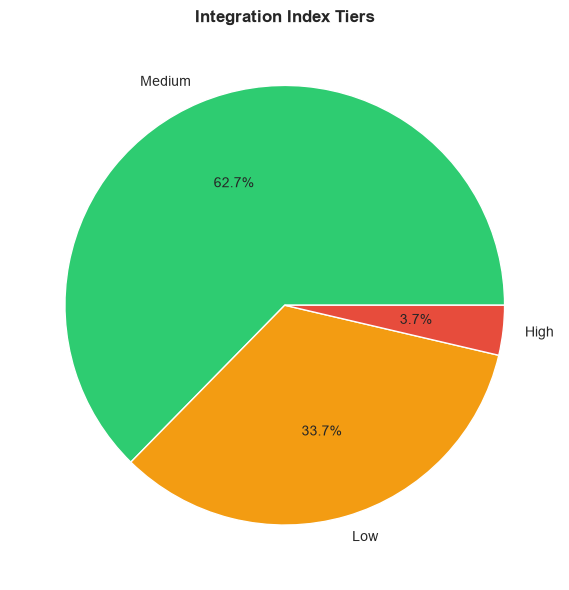

✓ Saved: 03_integration_tiers.png


In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
tier_dist.plot(kind='pie', autopct='%1.1f%%', colors=['#2ecc71', '#f39c12', '#e74c3c'], ax=ax)
ax.set_ylabel('')
ax.set_title('Integration Index Tiers', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('output/03_integration_tiers.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 03_integration_tiers.png')

## 5. Summary Table

In [11]:
summary = pd.DataFrame({
    'Component': components,
    'Weight': [weights[c] for c in components],
    'Mean Score': [master[c].mean() for c in components],
    'Std Dev': [master[c].std() for c in components],
    'Min': [master[c].min() for c in components],
    'Max': [master[c].max() for c in components]
})

summary['Contribution (Mean)'] = summary['Mean Score'] * summary['Weight']
summary = summary.round(2)
print(summary.to_string(index=False))

           Component  Weight  Mean Score  Std Dev   Min   Max  Contribution (Mean)
     employment_rate    0.20       46.88    19.08  0.00 100.0                 9.38
      housing_access    0.15       52.79    16.78  0.00 100.0                 7.92
education_enrollment    0.20       68.69    12.12 24.42 100.0                13.74
    income_stability    0.15       42.90    23.01  0.00 100.0                 6.44
  legal_rights_score    0.20       58.86    14.89 17.01 100.0                11.77
     social_cohesion    0.10       48.77    18.09  0.00 100.0                 4.88
